In [ ]:
# ================= CELL 1 =================
# QUESTION 3 — MULTI-INFRASTRUCTURE MAPPING
# Google Colab + GeoPandas + Matplotlib + Folium

PROJECT_TITLE = "Question 3 — Multi-Infrastructure Mapping | Google Colab + Folium"

print(PROJECT_TITLE)
print("Outputs:")
print("  1) Static 2×2 infrastructure map (PNG)")
print("  2) Interactive Folium web map (HTML)")


Question 3 — Multi-Infrastructure Mapping | Google Colab + Folium
Outputs:
  1) Static 2×2 infrastructure map (PNG)
  2) Interactive Folium web map (HTML)


In [ ]:
# ================= CELL 2 =================
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "geopandas": "geopandas",
    "pandas": "pandas",
    "shapely": "shapely",
    "matplotlib": "matplotlib",
    "folium": "folium",
    "pyogrio": "pyogrio",
    "matplotlib_scalebar": "matplotlib-scalebar",
}

missing = [
    pip_name
    for module_name, pip_name in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(module_name) is None
]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

from pathlib import Path
import tempfile
import zipfile
import html

import pandas as pd
import geopandas as gpd
import pyogrio
import shapely
from shapely.ops import unary_union

try:
    from shapely import make_valid
except ImportError:
    from shapely.validation import make_valid

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib_scalebar.scalebar import ScaleBar

import folium
from folium import plugins
from IPython.display import display, Image, HTML

print("GeoPandas:", gpd.__version__)
print("Shapely:", shapely.__version__)
print("Folium:", folium.__version__)


Installing missing packages: matplotlib-scalebar
GeoPandas: 1.1.4
Shapely: 2.1.2
Folium: 0.20.0


In [ ]:
# ================= CELL 3 =================
# CONFIGURATION — EDIT THE CLEARLY MARKED VALUES

DATA_DIR = Path("/content")

# ---- REQUIRED FILES: EDIT THESE NAMES ----
SCHOOLS_FILE = "Schools.shp"
HEALTH_FILE = "Health.shp"
ROADS_FILE = "Roads.shp"
RIVERS_FILE = "Rivers.shp"
DISTRICT_FILE = "Districts.shp"

# Optional layer names for GeoPackage / other multi-layer sources.
SCHOOLS_LAYER = None
HEALTH_LAYER = None
ROADS_LAYER = None
RIVERS_LAYER = None
DISTRICT_LAYER = None

DISTRICT_NAME = "Gasabo"       # Change if needed.
STUDENT_NAME = "ALEXIS NIYITEGEKA"     # <-- EDIT THIS

# Kigali is best handled in WGS 84 / UTM zone 36S for metric analysis.
# If your instructor explicitly requires EPSG:32735, change this value.
TARGET_CRS = "EPSG:32736"
WEB_CRS = "EPSG:4326"

SCHOOL_BUFFER_M = 1000
HEALTH_BUFFER_M = 5000
RIVER_BUFFER_M = 100

# Optional manual CRS overrides ONLY after verifying the source CRS.
SCHOOLS_CRS_OVERRIDE = None
HEALTH_CRS_OVERRIDE = None
ROADS_CRS_OVERRIDE = None
RIVERS_CRS_OVERRIDE = None
DISTRICT_CRS_OVERRIDE = None

# Optional CSV coordinate fields.
SCHOOLS_X_FIELD = None
SCHOOLS_Y_FIELD = None
HEALTH_X_FIELD = None
HEALTH_Y_FIELD = None

# Optional manual field overrides.
DISTRICT_FIELD = None
SCHOOL_NAME_FIELD = None
HEALTH_NAME_FIELD = None
ROAD_NAME_FIELD = None
ROAD_CATEGORY_FIELD = None
RIVER_NAME_FIELD = None

# Optional road styling overrides after inspecting real categories.
ROAD_STYLE_OVERRIDE = {}

OUTPUT_DIR = DATA_DIR / "question3_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

STATIC_PNG = OUTPUT_DIR / "static_infrastructure_4panel.png"
INTERACTIVE_HTML = OUTPUT_DIR / "interactive_infrastructure_map.html"

DATA_SOURCE_NOTE = (
    "User-provided schools, health facilities, roads, rivers and district boundary datasets."
)

print("Study district:", DISTRICT_NAME)
print("Metric CRS:", TARGET_CRS)
print("Output folder:", OUTPUT_DIR)

Study district: Gasabo
Metric CRS: EPSG:32736
Output folder: /content/question3_outputs


**Cell - 4**

In [ ]:
# ================= CELL 4 =================
def configured_path(filename):
    return DATA_DIR / filename

INPUTS = {
    "Schools": (configured_path(SCHOOLS_FILE), SCHOOLS_LAYER),
    "Health": (configured_path(HEALTH_FILE), HEALTH_LAYER),
    "Roads": (configured_path(ROADS_FILE), ROADS_LAYER),
    "Rivers": (configured_path(RIVERS_FILE), RIVERS_LAYER),
    "Districts": (configured_path(DISTRICT_FILE), DISTRICT_LAYER),
}

def inspect_container(label, path, layer=None):
    print("\n" + "=" * 72)
    print(label)
    print("Path:", path)

    if not path.exists():
        raise FileNotFoundError(
            f"{label}: file not found at {path}. "
            "Upload the file or correct the filename in Cell 3."
        )

    print("Extension:", path.suffix.lower())
    print("Size (MB):", round(path.stat().st_size / (1024 * 1024), 3))

    if path.suffix.lower() in {".gpkg", ".gdb", ".kml", ".geojson", ".json", ".shp"}:
        try:
            layers = pyogrio.list_layers(path)
            layer_df = pd.DataFrame(layers, columns=["Layer", "Geometry type"])
            print("Available vector layers:")
            display(layer_df)
            if layer is not None and layer not in set(layer_df["Layer"].astype(str)):
                print(f"WARNING: configured layer '{layer}' was not found.")
        except Exception as exc:
            print("Layer listing not available for this source:", exc)

for label, (path, layer) in INPUTS.items():
    inspect_container(label, path, layer)


Schools
Path: /content/Schools.shp
Extension: .shp
Size (MB): 0.073
Available vector layers:


,Layer,Geometry type
0,Schools,Point



Health
Path: /content/Health.shp
Extension: .shp
Size (MB): 0.011
Available vector layers:


,Layer,Geometry type
0,Health,Point



Roads
Path: /content/Roads.shp
Extension: .shp
Size (MB): 2.71
Available vector layers:


,Layer,Geometry type
0,Roads,LineString



Rivers
Path: /content/Rivers.shp
Extension: .shp
Size (MB): 1.259
Available vector layers:


,Layer,Geometry type
0,Rivers,LineString



Districts
Path: /content/Districts.shp
Extension: .shp
Size (MB): 1.141
Available vector layers:


,Layer,Geometry type
0,Districts,Polygon


In [ ]:
# ================= CELL 5 =================
LON_CANDIDATES = ["longitude", "lon", "lng", "long", "x", "xcoord", "x_coord"]
LAT_CANDIDATES = ["latitude", "lat", "y", "ycoord", "y_coord"]

def find_column_case_insensitive(columns, candidates):
    lookup = {str(c).strip().lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

def load_csv_points(path, x_field=None, y_field=None, source_crs="EPSG:4326"):
    df = pd.read_csv(path)

    if x_field is None:
        x_field = find_column_case_insensitive(df.columns, LON_CANDIDATES)
    if y_field is None:
        y_field = find_column_case_insensitive(df.columns, LAT_CANDIDATES)

    if x_field is None or y_field is None:
        raise ValueError(
            f"Could not detect coordinate columns in {path.name}. "
            f"Available columns: {list(df.columns)}. "
            "Set X/Y field overrides in Cell 3."
        )

    print(f"CSV coordinates detected: X='{x_field}', Y='{y_field}'")
    return gpd.GeoDataFrame(
        df.copy(),
        geometry=gpd.points_from_xy(df[x_field], df[y_field]),
        crs=source_crs,
    )

def load_vector(path, layer=None, label="Layer",
                x_field=None, y_field=None, crs_override=None):
    suffix = path.suffix.lower()

    if suffix == ".csv":
        gdf = load_csv_points(
            path,
            x_field=x_field,
            y_field=y_field,
            source_crs=crs_override or "EPSG:4326",
        )
    elif suffix == ".kmz":
        tmpdir = Path(tempfile.mkdtemp(prefix="kmz_"))
        with zipfile.ZipFile(path, "r") as zf:
            zf.extractall(tmpdir)
        kml_files = list(tmpdir.rglob("*.kml"))
        if not kml_files:
            raise ValueError(f"{label}: KMZ contains no KML file.")
        gdf = gpd.read_file(kml_files[0], layer=layer)
    elif suffix == ".zip":
        gdf = gpd.read_file(f"zip://{path}", layer=layer)
    else:
        kwargs = {}
        if layer is not None:
            kwargs["layer"] = layer
        gdf = gpd.read_file(path, **kwargs)

    if gdf.empty:
        raise ValueError(f"{label}: dataset loaded but contains zero features.")

    if "geometry" not in gdf.columns:
        raise ValueError(f"{label}: no geometry column was found.")

    if gdf.crs is None:
        if crs_override is not None:
            print(f"{label}: assigning manual CRS override {crs_override}")
            gdf = gdf.set_crs(crs_override, allow_override=True)
        else:
            raise ValueError(
                f"{label}: CRS is undefined. Verify the source CRS, then set "
                "the matching *_CRS_OVERRIDE in Cell 3."
            )

    return gdf

def report_gdf(label, gdf):
    print("\n" + "=" * 72)
    print(label)
    print("Rows:", len(gdf))
    print("CRS:", gdf.crs)
    print("Geometry types:", sorted(gdf.geom_type.dropna().unique().tolist()))
    print("Columns:", list(gdf.columns))
    print("Bounds [minx, miny, maxx, maxy]:", gdf.total_bounds)
    print("Invalid geometries:", int((~gdf.geometry.is_valid).sum()))
    print("Empty geometries:", int(gdf.geometry.is_empty.sum()))
    display(gdf.head(3))

schools = load_vector(
    INPUTS["Schools"][0], SCHOOLS_LAYER, "Schools",
    SCHOOLS_X_FIELD, SCHOOLS_Y_FIELD, SCHOOLS_CRS_OVERRIDE
)
health = load_vector(
    INPUTS["Health"][0], HEALTH_LAYER, "Health",
    HEALTH_X_FIELD, HEALTH_Y_FIELD, HEALTH_CRS_OVERRIDE
)
roads = load_vector(
    INPUTS["Roads"][0], ROADS_LAYER, "Roads",
    crs_override=ROADS_CRS_OVERRIDE
)
rivers = load_vector(
    INPUTS["Rivers"][0], RIVERS_LAYER, "Rivers",
    crs_override=RIVERS_CRS_OVERRIDE
)
districts = load_vector(
    INPUTS["Districts"][0], DISTRICT_LAYER, "Districts",
    crs_override=DISTRICT_CRS_OVERRIDE
)

for label, gdf in [
    ("Schools", schools),
    ("Health facilities", health),
    ("Roads", roads),
    ("Rivers", rivers),
    ("District boundary", districts),
]:
    report_gdf(label, gdf)


Schools
Rows: 2738
CRS: PROJCS["TM_Rwanda",GEOGCS["ITRF2005",DATUM["International_Terrestrial_Reference_Frame_2005",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6896"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",30],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",5000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Geometry types: ['Point']
Columns: ['OBJECTID', 'Type', 'Label', 'Name', 'CATEGORY', 'geometry']
Bounds [minx, miny, maxx, maxy]: [ 375335.378  4687873.444   594792.2403 4881377.4225]
Invalid geometries: 0
Empty geometries: 0


,OBJECTID,Type,Label,Name,CATEGORY,geometry
0,1,Secondary school,S.sc,None,2,POINT (546158.462 4879177.041)
1,2,Secondary school,S.sc,None,2,POINT (535365.341 4854895.883)
2,3,Secondary school,S.sc,None,2,POINT (538098.405 4859412.875)



Health facilities
Rows: 425
CRS: PROJCS["TM_Rwanda",GEOGCS["ITRF2005",DATUM["International_Terrestrial_Reference_Frame_2005",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6896"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",30],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",5000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Geometry types: ['Point']
Columns: ['OBJECTID', 'NEW_PROVIN', 'DISTRICT_N', 'NEW_SECTOR', 'UNIT_TYPE', 'PBFPHASE', 'Y', 'X', 'TYPE', 'Name', 'Category', 'geometry']
Bounds [minx, miny, maxx, maxy]: [ 376917.5566 4692595.408   594743.0812 4880938.0502]
Invalid geometries: 0
Empty geometries: 0


,OBJECTID,NEW_PROVIN,DISTRICT_N,NEW_SECTOR,UNIT_TYPE,PBFPHASE,Y,X,TYPE,Name,Category,geometry
0,1,EST,BUGESERA,GASHORA,2.0,0.0,-2.205534,30.24503,Health Centre,Gashora,3.0,POINT (527253.901 4756145.61)
1,2,EST,BUGESERA,KAMABUYE,2.0,0.0,-2.371917,30.13015,Health Centre,Kamabuye,3.0,POINT (514474.467 4737751.038)
2,3,EST,BUGESERA,MAREBA,2.0,0.0,-2.247817,30.07023,Health Centre,Mareba,3.0,POINT (507811.213 4751472.65)



Roads
Rows: 691
CRS: PROJCS["TM_Rwanda",GEOGCS["ITRF2005",DATUM["International_Terrestrial_Reference_Frame_2005",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6896"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",30],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",5000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Geometry types: ['LineString', 'MultiLineString']
Columns: ['OBJECTID', 'TYPE', 'ROAD_NO', 'SURFACE', 'SOURCE', 'CAPTURED', 'Shape_Leng', 'Order_', 'geometry']
Bounds [minx, miny, maxx, maxy]: [ 374077.295  4688536.864   590508.7345 4883695.0871]
Invalid geometries: 0
Empty geometries: 0


,OBJECTID,TYPE,ROAD_NO,SURFACE,SOURCE,CAPTURED,Shape_Leng,Order_,geometry
0,22100,District road,DR 29,Bridge,Orthophotos 2008/09,2010,20.823668,2,"LINESTRING (410718.215 4745923.819, 410704.486..."
1,22102,District road,DR 29,Bridge,Orthophotos 2008/09,2010,10.563829,2,"LINESTRING (412816.352 4745513.798, 412808.167..."
2,22106,District road,DR 29,Bridge,Orthophotos 2008/09,2010,14.088970,2,"LINESTRING (413732.261 4747151.502, 413726.624..."



Rivers
Rows: 37
CRS: PROJCS["TM_Rwanda",GEOGCS["ITRF2005",DATUM["International_Terrestrial_Reference_Frame_2005",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6896"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",30],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",5000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Geometry types: ['LineString', 'MultiLineString']
Columns: ['OBJECTID', 'Type', 'Name', 'Shape_Leng', 'geometry']
Bounds [minx, miny, maxx, maxy]: [ 373417.4987 4688227.6895  600014.0591 4884189.8996]
Invalid geometries: 0
Empty geometries: 0


,OBJECTID,Type,Name,Shape_Leng,geometry
0,747,1,Akanyaru,228.411056,"MULTILINESTRING ((454830.573 4689596.279, 4548..."
1,988,3,Agatobwe,35.491291,"LINESTRING (464562.658 4714762.326, 464520.851..."
2,1117,1,Mukungwa,40.564083,"LINESTRING (467526.542 4831630.179, 467453.067..."



District boundary
Rows: 30
CRS: PROJCS["TM_Rwanda",GEOGCS["ITRF2005",DATUM["International_Terrestrial_Reference_Frame_2005",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6896"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",30],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",5000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Geometry types: ['Polygon']
Columns: ['Name', 'Prov_ID', 'Province', 'POP_2002', 'POP_2012', 'Mayor', 'Area_Km2', 'Density_02', 'Growth', 'geometry']
Bounds [minx, miny, maxx, maxy]: [ 373407.7947 4685941.6856  600075.4008 4884219.096 ]
Invalid geometries: 0
Empty geometries: 0


,Name,Prov_ID,Province,POP_2002,POP_2012,Mayor,Area_Km2,Density_02,Growth,geometry
0,NYARUGENGE,1,KIGALI,236990,284860,Nzaramba Kaisiime,133.951,1769,20.1992,"POLYGON ((498703.054 4793478.642, 498771.335 4..."
1,GASABO,1,KIGALI,320516,530907,Rwamurangwa Steven,429.209,747,65.6413,"POLYGON ((515203.561 4803263.771, 515305.52 48..."
2,KICUKIRO,1,KIGALI,207819,319661,Dr Nyirahabimana Jeanne,166.706,1247,53.8170,"POLYGON ((517447.074 4783094.349, 517600.833 4..."


Cell-006

In [ ]:
# ================= CELL 6 =================
def clean_geometries(gdf, label):
    before = len(gdf)
    gdf = gdf[gdf.geometry.notna()].copy()
    gdf = gdf[~gdf.geometry.is_empty].copy()

    invalid_mask = ~gdf.geometry.is_valid
    invalid_count = int(invalid_mask.sum())

    if invalid_count:
        print(f"{label}: repairing {invalid_count} invalid geometries.")
        gdf.loc[invalid_mask, "geometry"] = gdf.loc[
            invalid_mask, "geometry"
        ].apply(make_valid)

    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()

    remaining_invalid = int((~gdf.geometry.is_valid).sum())
    if remaining_invalid:
        raise ValueError(
            f"{label}: {remaining_invalid} geometries remain invalid after repair."
        )

    print(
        f"{label}: {len(gdf)} valid/non-empty features retained; "
        f"{before - len(gdf)} removed."
    )
    return gdf

def assert_geometry_family(gdf, label, allowed_types):
    found = set(gdf.geom_type.dropna().unique())
    unexpected = found.difference(set(allowed_types))
    if unexpected:
        raise ValueError(
            f"{label}: unexpected geometry types {sorted(unexpected)}. "
            f"Expected one of {sorted(allowed_types)}."
        )

schools = clean_geometries(schools, "Schools")
health = clean_geometries(health, "Health facilities")
roads = clean_geometries(roads, "Roads")
rivers = clean_geometries(rivers, "Rivers")
districts = clean_geometries(districts, "District boundary")

assert_geometry_family(schools, "Schools", {"Point", "MultiPoint"})
assert_geometry_family(health, "Health facilities", {"Point", "MultiPoint"})
assert_geometry_family(roads, "Roads", {"LineString", "MultiLineString"})
assert_geometry_family(
    rivers, "Rivers",
    {"LineString", "MultiLineString", "Polygon", "MultiPolygon"}
)
assert_geometry_family(
    districts, "District boundary",
    {"Polygon", "MultiPolygon"}
)

river_types = set(rivers.geom_type.unique())
has_lake_polygons = bool(
    river_types.intersection({"Polygon", "MultiPolygon"})
)

if has_lake_polygons:
    print("Rivers source includes polygon water features that may represent lakes/waterbodies.")
else:
    print(
        "No polygon water features were supplied. "
        "The 'Rivers & Lakes' panel will use the available rivers only."
    )


Schools: 2738 valid/non-empty features retained; 0 removed.
Health facilities: 425 valid/non-empty features retained; 0 removed.
Roads: 691 valid/non-empty features retained; 0 removed.
Rivers: 37 valid/non-empty features retained; 0 removed.
District boundary: 30 valid/non-empty features retained; 0 removed.
No polygon water features were supplied. The 'Rivers & Lakes' panel will use the available rivers only.


Cell-007

In [ ]:
# ================= CELL 7 =================
DISTRICT_FIELD_CANDIDATES = [
    "district", "district_name", "dist_name", "adm2_name", "adm2_en",
    "name_2", "name2", "admin2", "name"
]

def find_likely_field(gdf, candidates, manual_override=None):
    if manual_override is not None:
        if manual_override not in gdf.columns:
            raise KeyError(
                f"Configured field '{manual_override}' not found. "
                f"Available fields: {list(gdf.columns)}"
            )
        return manual_override

    lookup = {str(c).lower(): c for c in gdf.columns}

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    for column in gdf.columns:
        clower = str(column).lower()
        if any(token in clower for token in ["district", "adm2", "name_2"]):
            return column

    return None

def select_district(gdf, district_name, field_override=None):
    if len(gdf) == 1:
        print("Boundary source contains one feature; using it.")
        selected = gdf.copy()
        chosen_field = None
    else:
        chosen_field = find_likely_field(
            gdf, DISTRICT_FIELD_CANDIDATES, field_override
        )
        if chosen_field is None:
            raise ValueError(
                "Could not detect a district-name field. "
                f"Available fields: {list(gdf.columns)}. "
                "Set DISTRICT_FIELD in Cell 3."
            )

        values = gdf[chosen_field].astype(str).str.strip()
        target = str(district_name).strip().casefold()
        exact = values.str.casefold() == target
        selected = gdf.loc[exact].copy()

        if selected.empty:
            contains = values.str.casefold().str.contains(target, regex=False)
            possible = gdf.loc[contains].copy()

            if len(possible) == 1:
                selected = possible
            else:
                sample = sorted(values.dropna().unique().tolist())[:30]
                raise ValueError(
                    f"District '{district_name}' was not uniquely found in "
                    f"'{chosen_field}'. Sample values: {sample}. "
                    "Check DISTRICT_NAME and DISTRICT_FIELD."
                )

    selected = selected[["geometry"]].dissolve().reset_index(drop=True)

    if selected.empty or selected.geometry.is_empty.any():
        raise ValueError("District selection produced an empty geometry.")

    print("Selected district:", district_name)
    print("Field used:", chosen_field if chosen_field else "single-feature source")
    return selected

district = select_district(districts, DISTRICT_NAME, DISTRICT_FIELD)
report_gdf(f"Selected district — {DISTRICT_NAME}", district)


Selected district: Gasabo
Field used: Name

Selected district — Gasabo
Rows: 1
CRS: PROJCS["TM_Rwanda",GEOGCS["ITRF2005",DATUM["International_Terrestrial_Reference_Frame_2005",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6896"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",30],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",5000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Geometry types: ['Polygon']
Columns: ['geometry']
Bounds [minx, miny, maxx, maxy]: [ 498775.7883 4779909.7047  530852.68   4803265.3727]
Invalid geometries: 0
Empty geometries: 0


,geometry
0,"POLYGON ((515203.561 4803263.771, 515305.52 48..."


Cell-008

In [ ]:
# ================= CELL 8 =================
def to_metric(gdf, label):
    if gdf.crs is None:
        raise ValueError(f"{label}: CRS is missing.")
    projected = gdf.to_crs(TARGET_CRS)
    print(f"{label}: {gdf.crs} -> {projected.crs}")
    return projected

district_m = to_metric(district, "District")
schools_m = to_metric(schools, "Schools")
health_m = to_metric(health, "Health facilities")
roads_m = to_metric(roads, "Roads")
rivers_m = to_metric(rivers, "Rivers")

schools_m = gpd.clip(schools_m, district_m)
health_m = gpd.clip(health_m, district_m)
roads_m = gpd.clip(roads_m, district_m)
rivers_m = gpd.clip(rivers_m, district_m)

for label, gdf in [
    ("Schools in district", schools_m),
    ("Health facilities in district", health_m),
    ("Roads in district", roads_m),
    ("Rivers/water features in district", rivers_m),
]:
    if gdf.empty:
        raise ValueError(
            f"{label}: zero features remain after clipping. "
            "Check source CRS, district selection and coverage."
        )
    print(f"{label}: {len(gdf)} features")

print("Projected analysis CRS:", district_m.crs)


District: PROJCS["TM_Rwanda",GEOGCS["ITRF2005",DATUM["International_Terrestrial_Reference_Frame_2005",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6896"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",30],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",5000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]] -> EPSG:32736
Schools: PROJCS["TM_Rwanda",GEOGCS["ITRF2005",DATUM["International_Terrestrial_Reference_Frame_2005",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6896"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",30],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northi

In [ ]:
# ================= CELL 9 =================
def make_dissolved_buffer(gdf, distance_m, district_gdf, label):
    if not gdf.crs or not gdf.crs.is_projected:
        raise ValueError(f"{label}: source must use a projected CRS.")

    buffered = gdf.geometry.buffer(distance_m)
    dissolved_geom = unary_union(buffered.tolist())

    dissolved = gpd.GeoDataFrame(
        {"buffer_m": [distance_m]},
        geometry=[dissolved_geom],
        crs=gdf.crs,
    )

    clipped = gpd.clip(dissolved, district_gdf)

    if clipped.empty:
        raise ValueError(f"{label}: buffer became empty after clipping.")

    area_km2 = clipped.geometry.area.sum() / 1_000_000

    print(
        f"{label}: {distance_m:,} m buffer | "
        f"clipped area ≈ {area_km2:,.2f} km²"
    )
    return clipped, area_km2

school_buffer_m, school_buffer_area_km2 = make_dissolved_buffer(
    schools_m, SCHOOL_BUFFER_M, district_m, "Schools"
)

health_buffer_m, health_buffer_area_km2 = make_dissolved_buffer(
    health_m, HEALTH_BUFFER_M, district_m, "Health facilities"
)

river_buffer_m, river_buffer_area_km2 = make_dissolved_buffer(
    rivers_m, RIVER_BUFFER_M, district_m, "Rivers"
)

buffer_stats = pd.DataFrame({
    "Layer": ["Schools", "Health facilities", "Rivers"],
    "Buffer_m": [SCHOOL_BUFFER_M, HEALTH_BUFFER_M, RIVER_BUFFER_M],
    "Buffered_area_km2": [
        school_buffer_area_km2,
        health_buffer_area_km2,
        river_buffer_area_km2,
    ],
})

display(buffer_stats)


Schools: 1,000 m buffer | clipped area ≈ 156.58 km²
Health facilities: 5,000 m buffer | clipped area ≈ 330.92 km²
Rivers: 100 m buffer | clipped area ≈ 4.88 km²


,Layer,Buffer_m,Buffered_area_km2
0,Schools,1000,156.579259
1,Health facilities,5000,330.916237
2,Rivers,100,4.879925


In [ ]:
# ================= CELL 10 =================
ROAD_CATEGORY_CANDIDATES = [
    "road_type", "roadtype", "category", "class", "highway",
    "road_class", "fclass", "type"
]

NAME_CANDIDATES = [
    "name", "name_en", "school_name", "facility_name", "health_name",
    "road_name", "river_name", "water_name", "label"
]

def detect_field(gdf, candidates, manual_override=None,
                 required=False, label="field"):
    field = find_likely_field(gdf, candidates, manual_override)

    if required and field is None:
        raise ValueError(
            f"Could not detect required {label}. "
            f"Available fields: {list(gdf.columns)}. "
            "Set the matching manual override in Cell 3."
        )
    return field

ROAD_CATEGORY_FIELD = detect_field(
    roads_m, ROAD_CATEGORY_CANDIDATES, ROAD_CATEGORY_FIELD,
    required=True, label="road category field"
)

SCHOOL_NAME_FIELD = detect_field(
    schools_m, NAME_CANDIDATES, SCHOOL_NAME_FIELD,
    label="school name field"
)
HEALTH_NAME_FIELD = detect_field(
    health_m, NAME_CANDIDATES, HEALTH_NAME_FIELD,
    label="health-facility name field"
)
ROAD_NAME_FIELD = detect_field(
    roads_m, NAME_CANDIDATES, ROAD_NAME_FIELD,
    label="road name field"
)
RIVER_NAME_FIELD = detect_field(
    rivers_m, NAME_CANDIDATES, RIVER_NAME_FIELD,
    label="river name field"
)

ROAD_CATEGORIES = sorted(
    roads_m[ROAD_CATEGORY_FIELD]
    .fillna("Unclassified")
    .astype(str)
    .str.strip()
    .replace("", "Unclassified")
    .unique()
    .tolist()
)

print("Road category field:", ROAD_CATEGORY_FIELD)
print("Unique road categories:")
for value in ROAD_CATEGORIES:
    print("  -", value)

ROAD_COLORS = [
    "#7F0000", "#D95F02", "#7570B3", "#1B9E77",
    "#E7298A", "#66A61E", "#A6761D", "#666666",
]
ROAD_WIDTHS = [3.3, 2.9, 2.5, 2.2, 1.9, 1.7, 1.5, 1.3]

ROAD_STYLE = {}
for index, category in enumerate(ROAD_CATEGORIES):
    ROAD_STYLE[category] = {
        "color": ROAD_COLORS[index % len(ROAD_COLORS)],
        "linewidth": ROAD_WIDTHS[min(index, len(ROAD_WIDTHS) - 1)],
    }

for category, style in ROAD_STYLE_OVERRIDE.items():
    if category not in ROAD_STYLE:
        print(f"WARNING: override category '{category}' is not present.")
        continue
    ROAD_STYLE[category].update(style)

display(pd.DataFrame([
    {
        "Category": category,
        "Color": style["color"],
        "Line width": style["linewidth"],
    }
    for category, style in ROAD_STYLE.items()
]))


Road category field: TYPE
Unique road categories:
  - District road
  - National road


,Category,Color,Line width
0,District road,#7F0000,3.3
1,National road,#D95F02,2.9


In [ ]:
# ================= CELL 11 =================
def add_display_fields(gdf, name_field=None,
                       type_field=None, default_type="Feature"):
    out = gdf.copy()

    if name_field is not None and name_field in out.columns:
        names = out[name_field].fillna("").astype(str).str.strip()
        out["display_name"] = names.mask(names.eq(""), "Unnamed feature")
    else:
        out["display_name"] = "Unnamed feature"

    if type_field is not None and type_field in out.columns:
        types = out[type_field].fillna("").astype(str).str.strip()
        out["display_type"] = types.mask(types.eq(""), default_type)
    else:
        out["display_type"] = default_type

    return out

schools_m = add_display_fields(
    schools_m, SCHOOL_NAME_FIELD, default_type="School"
)
health_m = add_display_fields(
    health_m, HEALTH_NAME_FIELD, default_type="Health facility"
)
roads_m = add_display_fields(
    roads_m, ROAD_NAME_FIELD, ROAD_CATEGORY_FIELD, default_type="Road"
)
rivers_m = add_display_fields(
    rivers_m, RIVER_NAME_FIELD, default_type="River / water feature"
)

district_w = district_m.to_crs(WEB_CRS)
schools_w = schools_m.to_crs(WEB_CRS)
health_w = health_m.to_crs(WEB_CRS)
roads_w = roads_m.to_crs(WEB_CRS)
rivers_w = rivers_m.to_crs(WEB_CRS)

school_buffer_w = school_buffer_m.to_crs(WEB_CRS)
health_buffer_w = health_buffer_m.to_crs(WEB_CRS)
river_buffer_w = river_buffer_m.to_crs(WEB_CRS)

district_area_km2 = district_m.geometry.area.sum() / 1_000_000

quality_report = pd.DataFrame({
    "Dataset": [
        "District", "Schools", "Health facilities",
        "Roads", "Rivers / water"
    ],
    "Features": [
        len(district_m), len(schools_m), len(health_m),
        len(roads_m), len(rivers_m)
    ],
    "CRS": [
        str(district_m.crs), str(schools_m.crs), str(health_m.crs),
        str(roads_m.crs), str(rivers_m.crs)
    ],
    "All_valid": [
        bool(district_m.geometry.is_valid.all()),
        bool(schools_m.geometry.is_valid.all()),
        bool(health_m.geometry.is_valid.all()),
        bool(roads_m.geometry.is_valid.all()),
        bool(rivers_m.geometry.is_valid.all()),
    ],
})

print(f"District area ≈ {district_area_km2:,.2f} km²")
display(quality_report)
display(buffer_stats)


District area ≈ 430.02 km²


,Dataset,Features,CRS,All_valid
0,District,1,EPSG:32736,True
1,Schools,94,EPSG:32736,True
2,Health facilities,15,EPSG:32736,True
3,Roads,19,EPSG:32736,True
4,Rivers / water,1,EPSG:32736,True


,Layer,Buffer_m,Buffered_area_km2
0,Schools,1000,156.579259
1,Health facilities,5000,330.916237
2,Rivers,100,4.879925


Cell-12

Static figure created. Save it in Cell 13.


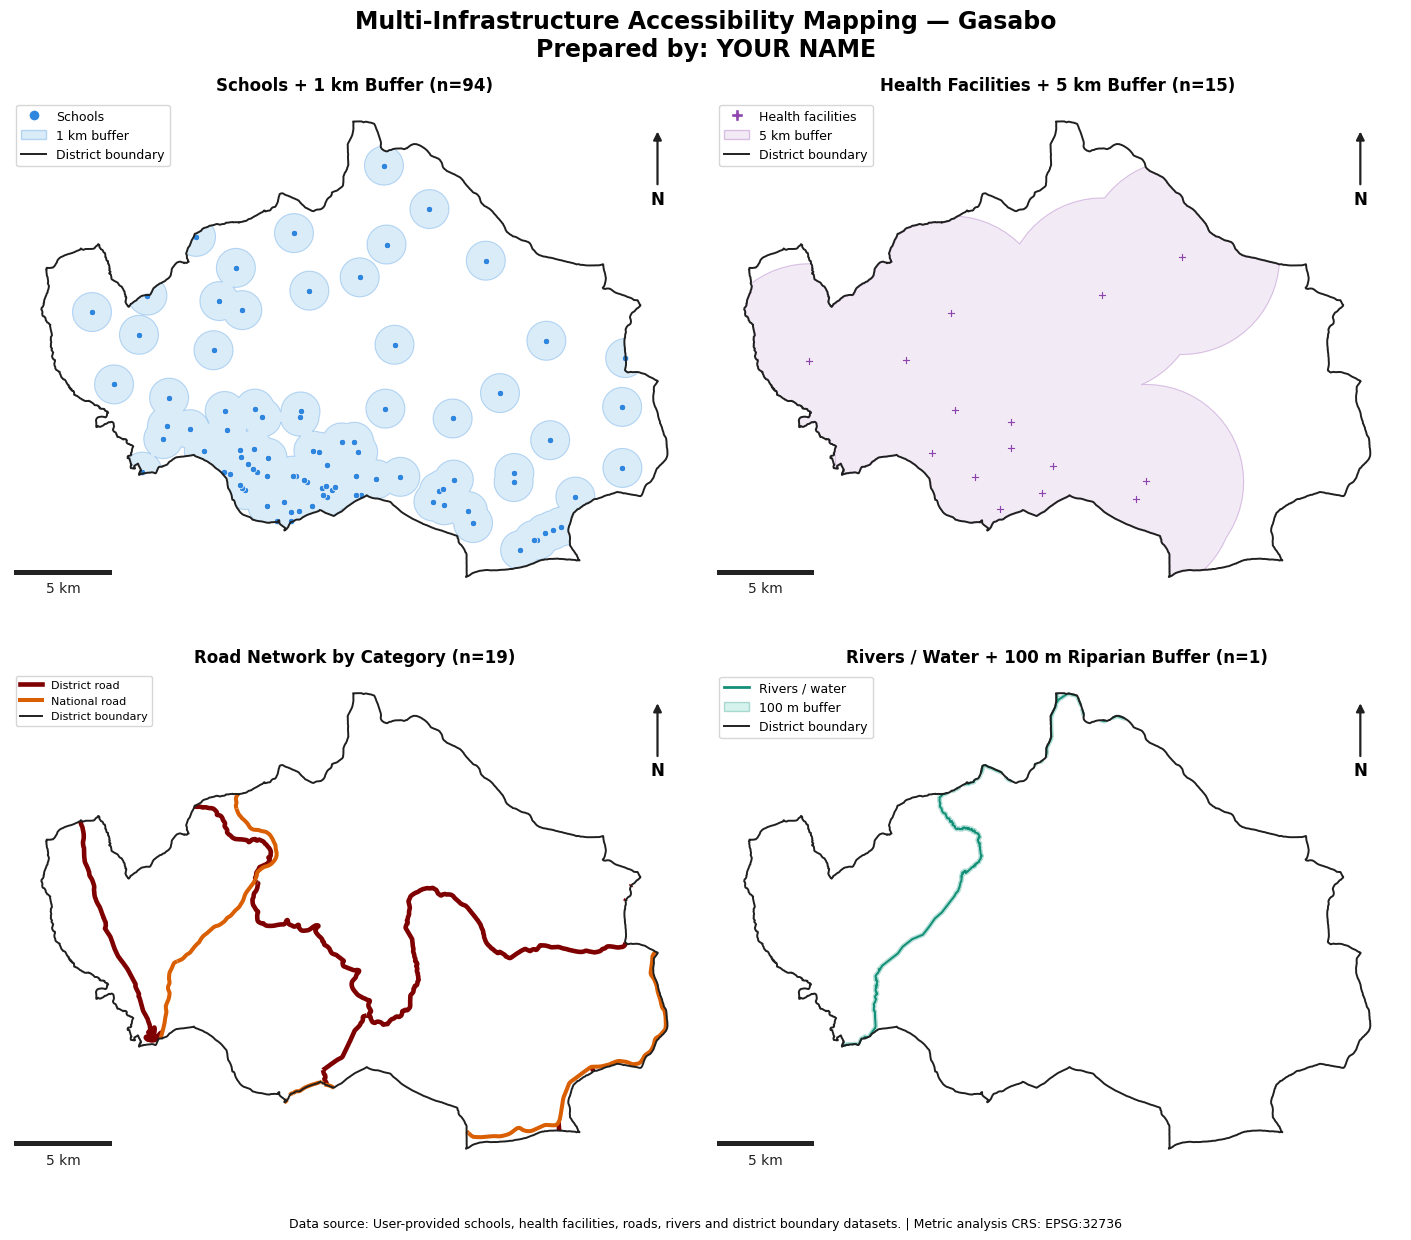

In [ ]:
# ================= CELL 12 =================
DISTRICT_EDGE = "#202020"
SCHOOL_COLOR = "#2E86DE"
SCHOOL_BUFFER_COLOR = "#85C1E9"
HEALTH_COLOR = "#8E44AD"
HEALTH_BUFFER_COLOR = "#D7BDE2"
RIVER_COLOR = "#148F77"
RIVER_BUFFER_COLOR = "#76D7C4"
BUFFER_ALPHA = 0.30

minx, miny, maxx, maxy = district_m.total_bounds
width = maxx - minx
height = maxy - miny
pad_x = width * 0.05
pad_y = height * 0.05
COMMON_EXTENT = (
    minx - pad_x, maxx + pad_x,
    miny - pad_y, maxy + pad_y,
)

def apply_common_map_format(ax):
    ax.set_xlim(COMMON_EXTENT[0], COMMON_EXTENT[1])
    ax.set_ylim(COMMON_EXTENT[2], COMMON_EXTENT[3])
    ax.set_aspect("equal")
    ax.set_axis_off()

    ax.add_artist(ScaleBar(
        dx=1,
        units="m",
        location="lower left",
        box_alpha=0.65,
        color="#222222",
        frameon=True,
    ))

    ax.annotate(
        "N",
        xy=(0.94, 0.94),
        xytext=(0.94, 0.80),
        xycoords="axes fraction",
        textcoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="-|>",
            color="#202020",
            lw=1.6,
        ),
    )

def plot_district(ax):
    district_m.boundary.plot(
        ax=ax,
        color=DISTRICT_EDGE,
        linewidth=1.4,
        zorder=10,
    )

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 12),
    constrained_layout=True,
)
ax1, ax2, ax3, ax4 = axes.ravel()

# PANEL 1 — Schools
school_buffer_m.plot(
    ax=ax1,
    color=SCHOOL_BUFFER_COLOR,
    alpha=BUFFER_ALPHA,
    edgecolor=SCHOOL_COLOR,
    linewidth=0.8,
    zorder=1,
)
schools_m.plot(
    ax=ax1,
    color=SCHOOL_COLOR,
    marker="o",
    markersize=22,
    edgecolor="white",
    linewidth=0.5,
    zorder=5,
)
plot_district(ax1)
ax1.set_title(
    f"Schools + {SCHOOL_BUFFER_M/1000:g} km Buffer (n={len(schools_m)})",
    fontsize=12,
    fontweight="bold",
)
ax1.legend(
    handles=[
        Line2D([0], [0], marker="o", color="none",
               markerfacecolor=SCHOOL_COLOR, markeredgecolor="white",
               markersize=8, label="Schools"),
        Patch(facecolor=SCHOOL_BUFFER_COLOR, edgecolor=SCHOOL_COLOR,
              alpha=BUFFER_ALPHA,
              label=f"{SCHOOL_BUFFER_M/1000:g} km buffer"),
        Line2D([0], [0], color=DISTRICT_EDGE, lw=1.4,
               label="District boundary"),
    ],
    loc="upper left",
    fontsize=9,
)
apply_common_map_format(ax1)

# PANEL 2 — Health
health_buffer_m.plot(
    ax=ax2,
    color=HEALTH_BUFFER_COLOR,
    alpha=BUFFER_ALPHA,
    edgecolor=HEALTH_COLOR,
    linewidth=0.8,
    zorder=1,
)
health_m.plot(
    ax=ax2,
    color=HEALTH_COLOR,
    marker="P",
    markersize=28,
    edgecolor="white",
    linewidth=0.5,
    zorder=5,
)
plot_district(ax2)
ax2.set_title(
    f"Health Facilities + {HEALTH_BUFFER_M/1000:g} km Buffer (n={len(health_m)})",
    fontsize=12,
    fontweight="bold",
)
ax2.legend(
    handles=[
        Line2D([0], [0], marker="P", color="none",
               markerfacecolor=HEALTH_COLOR, markeredgecolor="white",
               markersize=9, label="Health facilities"),
        Patch(facecolor=HEALTH_BUFFER_COLOR, edgecolor=HEALTH_COLOR,
              alpha=BUFFER_ALPHA,
              label=f"{HEALTH_BUFFER_M/1000:g} km buffer"),
        Line2D([0], [0], color=DISTRICT_EDGE, lw=1.4,
               label="District boundary"),
    ],
    loc="upper left",
    fontsize=9,
)
apply_common_map_format(ax2)

# PANEL 3 — Roads by category
road_legend = []

for category in ROAD_CATEGORIES:
    category_values = (
        roads_m[ROAD_CATEGORY_FIELD]
        .fillna("Unclassified")
        .astype(str)
        .str.strip()
        .replace("", "Unclassified")
    )
    subset = roads_m[category_values == category]
    style = ROAD_STYLE[category]

    subset.plot(
        ax=ax3,
        color=style["color"],
        linewidth=style["linewidth"],
        zorder=4,
    )
    road_legend.append(
        Line2D(
            [0], [0],
            color=style["color"],
            lw=style["linewidth"],
            label=category,
        )
    )

plot_district(ax3)
road_legend.append(
    Line2D([0], [0], color=DISTRICT_EDGE, lw=1.4,
           label="District boundary")
)
ax3.set_title(
    f"Road Network by Category (n={len(roads_m)})",
    fontsize=12,
    fontweight="bold",
)
ax3.legend(
    handles=road_legend,
    loc="upper left",
    fontsize=8,
)
apply_common_map_format(ax3)

# PANEL 4 — Rivers / water
river_buffer_m.plot(
    ax=ax4,
    color=RIVER_BUFFER_COLOR,
    alpha=BUFFER_ALPHA,
    edgecolor=RIVER_COLOR,
    linewidth=0.6,
    zorder=1,
)
rivers_m.plot(
    ax=ax4,
    color=RIVER_COLOR,
    linewidth=1.5,
    zorder=5,
)
plot_district(ax4)
ax4.set_title(
    f"Rivers / Water + {RIVER_BUFFER_M:g} m Riparian Buffer (n={len(rivers_m)})",
    fontsize=12,
    fontweight="bold",
)
ax4.legend(
    handles=[
        Line2D([0], [0], color=RIVER_COLOR, lw=2.0,
               label="Rivers / water"),
        Patch(facecolor=RIVER_BUFFER_COLOR, edgecolor=RIVER_COLOR,
              alpha=BUFFER_ALPHA,
              label=f"{RIVER_BUFFER_M:g} m buffer"),
        Line2D([0], [0], color=DISTRICT_EDGE, lw=1.4,
               label="District boundary"),
    ],
    loc="upper left",
    fontsize=9,
)
apply_common_map_format(ax4)

fig.suptitle(
    f"Multi-Infrastructure Accessibility Mapping — {DISTRICT_NAME}\n"
    f"Prepared by: {STUDENT_NAME}",
    fontsize=17,
    fontweight="bold",
)

fig.text(
    0.5,
    -0.01,
    f"Data source: {DATA_SOURCE_NOTE} | Metric analysis CRS: {TARGET_CRS}",
    ha="center",
    va="top",
    fontsize=9,
)

print("Static figure created. Save it in Cell 13.")


Saved: /content/question3_outputs/static_infrastructure_4panel.png
File size (MB): 1.04


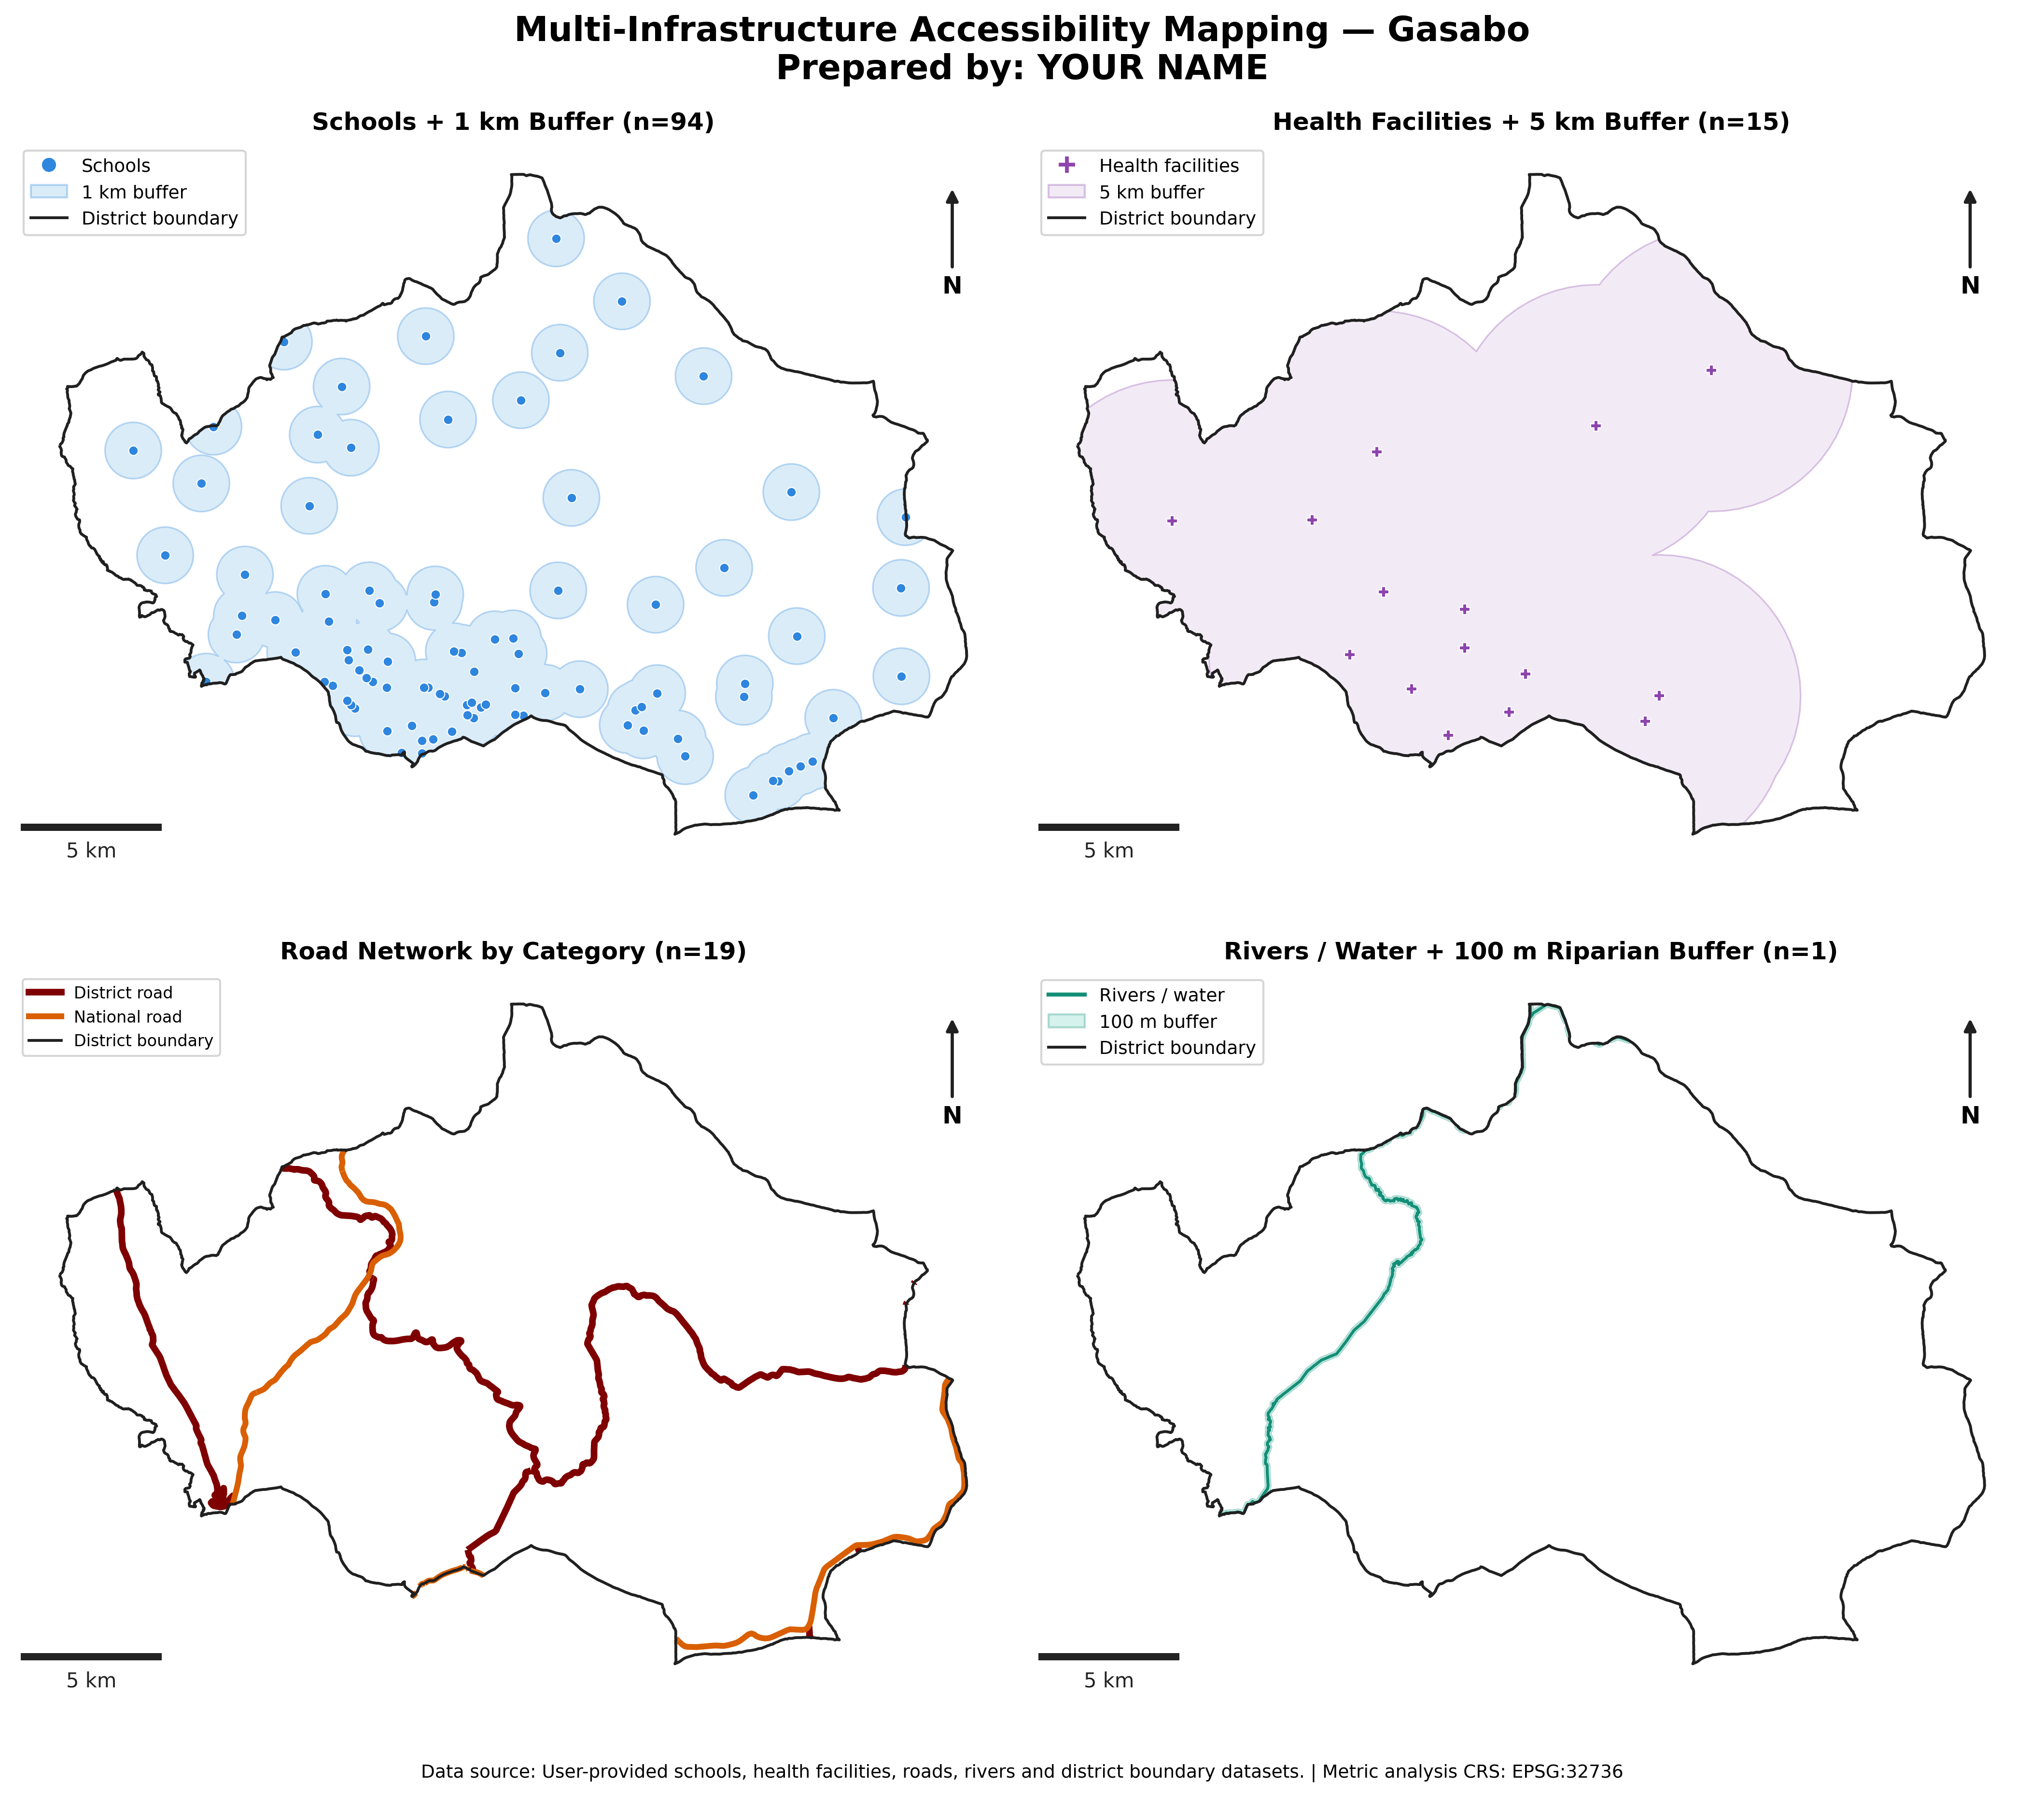

In [ ]:
# ================= CELL 13 =================
fig.savefig(
    STATIC_PNG,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

if not STATIC_PNG.exists():
    raise RuntimeError(f"Static PNG was not created: {STATIC_PNG}")

print("Saved:", STATIC_PNG)
print("File size (MB):", round(STATIC_PNG.stat().st_size / (1024 * 1024), 2))
display(Image(filename=str(STATIC_PNG)))


In [ ]:
# ================= CELL 14 =================
def safe_popup_html(name, feature_type, extra=None):
    rows = [
        f"<b>Name:</b> {html.escape(str(name))}",
        f"<b>Type:</b> {html.escape(str(feature_type))}",
    ]
    if extra:
        for key, value in extra.items():
            if value is None or (isinstance(value, float) and pd.isna(value)):
                continue
            rows.append(
                f"<b>{html.escape(str(key))}:</b> {html.escape(str(value))}"
            )
    return "<br>".join(rows)

def add_point_features(gdf, group, color, radius=5):
    for _, row in gdf.iterrows():
        geom = row.geometry
        points = list(geom.geoms) if geom.geom_type == "MultiPoint" else [geom]

        for point in points:
            popup = safe_popup_html(
                row.get("display_name", "Unnamed feature"),
                row.get("display_type", "Feature"),
            )
            folium.CircleMarker(
                location=[point.y, point.x],
                radius=radius,
                color="white",
                weight=1,
                fill=True,
                fill_color=color,
                fill_opacity=0.95,
                tooltip=row.get("display_name", "Unnamed feature"),
                popup=folium.Popup(popup, max_width=320),
            ).add_to(group)

def add_line_or_polygon_features(gdf, group, color, weight=2):
    for _, row in gdf.iterrows():
        popup = safe_popup_html(
            row.get("display_name", "Unnamed feature"),
            row.get("display_type", "Feature"),
        )

        feature = gpd.GeoSeries(
            [row.geometry],
            crs=gdf.crs
        ).__geo_interface__

        folium.GeoJson(
            feature,
            style_function=lambda _feature, c=color, w=weight: {
                "color": c,
                "weight": w,
                "fillColor": c,
                "fillOpacity": 0.15,
            },
            tooltip=row.get("display_name", "Unnamed feature"),
            popup=folium.Popup(popup, max_width=320),
        ).add_to(group)

def add_dissolved_buffer(gdf, group, fill_color, label, fill_opacity=0.22):
    folium.GeoJson(
        gdf.__geo_interface__,
        name=label,
        style_function=lambda _feature, c=fill_color, a=fill_opacity: {
            "color": c,
            "weight": 1.2,
            "fillColor": c,
            "fillOpacity": a,
        },
        tooltip=label,
    ).add_to(group)

district_centroid_w = gpd.GeoSeries(
    [district_m.geometry.iloc[0].centroid],
    crs=TARGET_CRS,
).to_crs(WEB_CRS).iloc[0]

west, south, east, north = district_w.total_bounds

m = folium.Map(
    location=[district_centroid_w.y, district_centroid_w.x],
    zoom_start=11,
    tiles=None,
    control_scale=True,
    prefer_canvas=True,
)

folium.TileLayer(
    "CartoDB positron",
    name="Light basemap",
    control=True,
    show=True,
).add_to(m)

folium.TileLayer(
    "OpenStreetMap",
    name="OpenStreetMap",
    control=True,
    show=False,
).add_to(m)

district_group = folium.FeatureGroup(
    name="District Boundary",
    show=True,
)
school_group = folium.FeatureGroup(
    name=f"Schools — {SCHOOL_BUFFER_M/1000:g} km buffer",
    show=True,
)
health_group = folium.FeatureGroup(
    name=f"Health Facilities — {HEALTH_BUFFER_M/1000:g} km buffer",
    show=False,
)
road_group = folium.FeatureGroup(
    name="Roads — by category",
    show=True,
)
river_group = folium.FeatureGroup(
    name=f"Rivers / Water — {RIVER_BUFFER_M:g} m buffer",
    show=True,
)

folium.GeoJson(
    district_w.__geo_interface__,
    style_function=lambda _feature: {
        "color": "#202020",
        "weight": 3,
        "fillOpacity": 0,
    },
    tooltip=f"{DISTRICT_NAME} district boundary",
).add_to(district_group)

add_dissolved_buffer(
    school_buffer_w,
    school_group,
    SCHOOL_BUFFER_COLOR,
    f"School buffer — {SCHOOL_BUFFER_M/1000:g} km",
)
add_point_features(
    schools_w,
    school_group,
    SCHOOL_COLOR,
    radius=5,
)

add_dissolved_buffer(
    health_buffer_w,
    health_group,
    HEALTH_BUFFER_COLOR,
    f"Health buffer — {HEALTH_BUFFER_M/1000:g} km",
)
add_point_features(
    health_w,
    health_group,
    HEALTH_COLOR,
    radius=6,
)

for _, row in roads_w.iterrows():
    category = str(
        row.get(ROAD_CATEGORY_FIELD, "Unclassified")
    ).strip() or "Unclassified"

    style = ROAD_STYLE.get(
        category,
        {"color": "#666666", "linewidth": 1.5},
    )

    popup = safe_popup_html(
        row.get("display_name", "Unnamed feature"),
        category,
    )

    feature = gpd.GeoSeries(
        [row.geometry],
        crs=roads_w.crs
    ).__geo_interface__

    folium.GeoJson(
        feature,
        style_function=lambda _feature, s=style: {
            "color": s["color"],
            "weight": max(2, s["linewidth"]),
            "opacity": 0.9,
        },
        tooltip=f"{row.get('display_name', 'Unnamed feature')} | {category}",
        popup=folium.Popup(popup, max_width=320),
    ).add_to(road_group)

add_dissolved_buffer(
    river_buffer_w,
    river_group,
    RIVER_BUFFER_COLOR,
    f"Riparian buffer — {RIVER_BUFFER_M:g} m",
)
add_line_or_polygon_features(
    rivers_w,
    river_group,
    RIVER_COLOR,
    weight=2,
)

for group in [
    district_group,
    school_group,
    health_group,
    road_group,
    river_group,
]:
    group.add_to(m)

info_html = f"""
<div style="
    position: fixed;
    top: 12px;
    left: 50px;
    z-index: 9999;
    width: 390px;
    max-width: calc(100% - 80px);
    background: rgba(255,255,255,0.94);
    border: 1px solid #666;
    border-radius: 6px;
    padding: 10px 12px;
    font-family: Arial, sans-serif;
    font-size: 12px;
    box-shadow: 0 1px 4px rgba(0,0,0,0.25);
">
    <div style="font-size:15px;font-weight:700;margin-bottom:4px;">
        Multi-Infrastructure Mapping — {html.escape(DISTRICT_NAME)}
    </div>
    <div><b>Prepared by:</b> {html.escape(STUDENT_NAME)}</div>
    <div><b>Buffers:</b> Schools {SCHOOL_BUFFER_M/1000:g} km |
         Health {HEALTH_BUFFER_M/1000:g} km |
         Rivers {RIVER_BUFFER_M:g} m</div>
    <div><b>Source:</b> {html.escape(DATA_SOURCE_NOTE)}</div>
</div>
"""
m.get_root().html.add_child(folium.Element(info_html))

folium.LayerControl(collapsed=False).add_to(m)
plugins.Fullscreen(position="topright").add_to(m)
plugins.MiniMap(toggle_display=True).add_to(m)

m.fit_bounds([[south, west], [north, east]])
display(m)


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [ ]:
# ================= CELL 15 =================
m.save(str(INTERACTIVE_HTML))

if not INTERACTIVE_HTML.exists():
    raise RuntimeError(f"Interactive HTML was not created: {INTERACTIVE_HTML}")

print("Saved:", INTERACTIVE_HTML)
print("File size (MB):", round(INTERACTIVE_HTML.stat().st_size / (1024 * 1024), 2))

display(
    HTML(
        f'<a href="files/{INTERACTIVE_HTML.name}" target="_blank">'
        "Open interactive infrastructure map"
        "</a>"
    )
)


Saved: /content/question3_outputs/interactive_infrastructure_map.html
File size (MB): 0.74


In [ ]:
# ================= CELL 16 =================
print("=" * 72)
print("QUESTION 3 — FINAL OUTPUTS")
print("=" * 72)

for output_path in [STATIC_PNG, INTERACTIVE_HTML]:
    status = "OK" if output_path.exists() else "MISSING"
    print(f"[{status}] {output_path}")

print("\nStudy area:", DISTRICT_NAME)
print("Student:", STUDENT_NAME)
print("Metric CRS:", TARGET_CRS)
print("Web-map CRS:", WEB_CRS)

print("\nFeature counts")
print("  Schools:", len(schools_m))
print("  Health facilities:", len(health_m))
print("  Roads:", len(roads_m))
print("  Rivers / water features:", len(rivers_m))

print("\nApproximate clipped buffer areas")
print(f"  Schools ({SCHOOL_BUFFER_M:,} m): {school_buffer_area_km2:,.2f} km²")
print(f"  Health ({HEALTH_BUFFER_M:,} m): {health_buffer_area_km2:,.2f} km²")
print(f"  Rivers ({RIVER_BUFFER_M:,} m): {river_buffer_area_km2:,.2f} km²")

print("\nSUBMISSION CHECKLIST")
checklist = [
    "Static 2×2 map saved as a 300-DPI PNG",
    "Panel 1 shows schools and 1 km buffer",
    "Panel 2 shows health facilities and 5 km buffer",
    "Panel 3 shows roads styled by actual road category",
    "Panel 4 shows rivers/water and 100 m riparian buffer",
    "All four panels use the same district extent",
    "District boundary appears on every static panel",
    "Static map includes title, student name, legends, north arrows and scale bars",
    "Interactive Folium map is centred/fitted on the district",
    "Interactive layers are separately toggleable",
    "Infrastructure features have names/types in popups",
    "Buffers are semi-transparent overlays",
    "Interactive HTML is saved",
    "Data source note is included",
    "Notebook is saved and shared from Google Colab",
]

for item in checklist:
    print("  [ ]", item)

print("\nOPTIONAL DOWNLOAD FROM COLAB")
print("Uncomment the lines below when ready:")
print("# from google.colab import files")
print("# files.download(str(STATIC_PNG))")
print("# files.download(str(INTERACTIVE_HTML))")


QUESTION 3 — FINAL OUTPUTS
[OK] /content/question3_outputs/static_infrastructure_4panel.png
[OK] /content/question3_outputs/interactive_infrastructure_map.html

Study area: Gasabo
Student: BRANCAL
Metric CRS: EPSG:32736
Web-map CRS: EPSG:4326

Feature counts
  Schools: 94
  Health facilities: 15
  Roads: 19
  Rivers / water features: 1

Approximate clipped buffer areas
  Schools (1,000 m): 156.58 km²
  Health (5,000 m): 330.92 km²
  Rivers (100 m): 4.88 km²

SUBMISSION CHECKLIST
  [ ] Static 2×2 map saved as a 300-DPI PNG
  [ ] Panel 1 shows schools and 1 km buffer
  [ ] Panel 2 shows health facilities and 5 km buffer
  [ ] Panel 3 shows roads styled by actual road category
  [ ] Panel 4 shows rivers/water and 100 m riparian buffer
  [ ] All four panels use the same district extent
  [ ] District boundary appears on every static panel
  [ ] Static map includes title, student name, legends, north arrows and scale bars
  [ ] Interactive Folium map is centred/fitted on the district
  [ ] 